# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az

NETID = 'ahuwer2'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

In [2]:
from astropy.cosmology import FlatLambdaCDM

sn = pd.read_csv(MIDTERM + 'p2_pantheon_sne.csv')
z = sn['z'].to_numpy()
mu_all = FlatLambdaCDM(H0=70, Om0=0.3).distmod(z).value
mB_all, x1_all, c_all = sn['mB'].to_numpy(), sn['x1'].to_numpy(), sn['c'].to_numpy()
step_all = (sn['host_logmass'].to_numpy() > 10).astype(float)
pec2_all = (5/np.log(10) * 250/(299792.458*z))**2
C_all = np.zeros((len(sn), 3, 3))
C_all[:, 0, 0], C_all[:, 1, 1], C_all[:, 2, 2] = sn['mB_err']**2, sn['x1_err']**2, sn['c_err']**2
C_all[:, 0, 1] = C_all[:, 1, 0] = sn['cov_mB_x1']
C_all[:, 0, 2] = C_all[:, 2, 0] = sn['cov_mB_c']
C_all[:, 1, 2] = C_all[:, 2, 1] = sn['cov_x1_c']

# contaminants: same iterative 7.5-sigma MAD clip as the midterm (2a)
res = mB_all - mu_all
A = np.column_stack([x1_all, c_all, np.ones(len(sn))])
keep = np.ones(len(sn), bool)
for _ in range(2):
    coef = np.linalg.lstsq(A[keep], res[keep], rcond=None)[0]
    dev = res - A @ coef
    mad = 1.4826*np.median(np.abs(dev[keep] - np.median(dev[keep])))
    keep = np.abs(dev) < 7.5*mad
d_int = coef[2]                       # plane intercept, centers the prior on M like the midterm

mB, x1, c, mu, step, pec2, C = (a[keep] for a in (mB_all, x1_all, c_all, mu_all, step_all, pec2_all, C_all))
N = keep.sum()
print(f"{N} SNe kept, {(~keep).sum()} removed")

# centered vs non-centered: compare measurement errors with population widths
print(f"x1: median err = {np.median(np.sqrt(C[:,1,1])):.3f}, spread = {x1.std():.3f}")
print(f"c : median err = {np.median(np.sqrt(C[:,2,2])):.3f}, spread = {c.std():.3f}")

246 SNe kept, 4 removed
x1: median err = 0.166, spread = 1.036
c : median err = 0.033, spread = 0.093


In [3]:
y = np.column_stack([mB, x1, c])
E00 = np.zeros((3, 3)); E00[0, 0] = 1.0
print(N)

with pm.Model() as latent_model:
    # same priors as the midterm
    M      = pm.Uniform('M', d_int-3, d_int+3)
    alpha  = pm.Uniform('alpha', -2, 2)
    beta   = pm.Uniform('beta', -10, 10)
    gamma  = pm.Uniform('gamma', -1, 1)
    lnsig  = pm.Uniform('lnsig', np.log(1e-3), 0.0)
    sig_int = pm.Deterministic('sigma_int', pt.exp(lnsig))
    # populations (weak priors)
    mu_x, sig_x = pm.Normal('mu_x', 0, 5), pm.HalfNormal('sig_x', 5)
    mu_c, sig_c = pm.Normal('mu_c', 0, 1), pm.HalfNormal('sig_c', 1)
    # latent true values, CENTERED (measurement errors << population widths, see above)
    x1_true = pm.Normal('x1_true', mu_x, sig_x, shape=int(N), initval=x1)
    c_true  = pm.Normal('c_true',  mu_c, sig_c, shape=int(N), initval=c)

    mean = pt.stack([M + mu - alpha*x1_true + beta*c_true + gamma*step, x1_true, c_true], axis=1)
    cov  = C + (sig_int**2 + pec2)[:, None, None] * E00     # sigma_int^2 + pec only on the m_B entry
    pm.MvNormal('obs', mu=mean, cov=cov, observed=y)

    idata = pm.sample(4000, tune=2000, chains=4, target_accept=0.9, random_seed=42)

summ = az.summary(idata)
ndiv = int(idata.sample_stats['diverging'].values.sum())
print(f"max Rhat = {summ['r_hat'].max():.3f}, min bulk ESS = {summ['ess_bulk'].min():.0f}, divergences = {ndiv}")

def q(name):
    lo, med, hi = np.percentile(idata.posterior[name].values.ravel(), [16, 50, 84])
    return f"{med:.4f} +{hi-med:.4f} -{med-lo:.4f}"

mid = {'alpha': '0.1349 +0.0099 -0.0098', 'beta': '2.8739 +0.1049 -0.1065',
       'gamma': '-0.0370 +0.0201 -0.0200', 'sigma_int': '0.1185 +0.0089 -0.0085'}
print(pd.DataFrame({'midterm': mid, 'latent model': {k: q(k) for k in mid}}))

246


c:\Users\Austin\miniforge3\envs\astr457\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, lnsig, mu_x, sig_x, mu_c, sig_c, x1_true, c_true]


Output()

Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 99 seconds.


max Rhat = 1.002, min bulk ESS = 9757, divergences = 0
                           midterm             latent model
alpha       0.1349 +0.0099 -0.0098   0.1427 +0.0101 -0.0102
beta        2.8739 +0.1049 -0.1065   3.1283 +0.1243 -0.1237
gamma      -0.0370 +0.0201 -0.0200  -0.0391 +0.0197 -0.0196
sigma_int   0.1185 +0.0089 -0.0085   0.1151 +0.0091 -0.0087


In [4]:
def nll_mid(th, mB_, x1_, c_):
    """Your 2b likelihood."""
    M, al, be, ga, lns = th
    r = mB_ - mu - M + al*x1_ - be*c_ - ga*step
    var = (C[:,0,0] + al**2*C[:,1,1] + be**2*C[:,2,2] + 2*al*C[:,0,1] - 2*be*C[:,0,2]
           - 2*al*be*C[:,1,2] + pec2 + np.exp(2*lns))
    return 0.5*np.sum(r**2/var + np.log(var) + np.log(2*np.pi))

def nll_lat(th, mB_, x1_, c_):
    """True x1, c integrated out: (mB, x1, c)_i ~ N(mean, C_i + diag(sig_int^2+pec^2,0,0) + A Sigma_pop A^T)."""
    M, al, be, ga, lns, mx, lsx, mc, lsc = th
    sx2, sc2 = np.exp(2*lsx), np.exp(2*lsc)
    mean = np.column_stack([M + mu - al*mx + be*mc + ga*step, np.full(N, mx), np.full(N, mc)])
    S = C.copy()
    S[:, 0, 0] += np.exp(2*lns) + pec2 + al**2*sx2 + be**2*sc2
    S[:, 0, 1] += -al*sx2;  S[:, 1, 0] += -al*sx2
    S[:, 0, 2] += be*sc2;   S[:, 2, 0] += be*sc2
    S[:, 1, 1] += sx2;      S[:, 2, 2] += sc2
    d = np.column_stack([mB_, x1_, c_]) - mean
    sol = np.linalg.solve(S, d[:, :, None])[:, :, 0]
    return 0.5*np.sum(np.sum(d*sol, axis=1) + np.linalg.slogdet(S)[1] + 3*np.log(2*np.pi))

def fit_both(mB_, x1_, c_):
    s = np.linalg.lstsq(np.column_stack([np.ones(N), -x1_, c_, step]), mB_ - mu, rcond=None)[0]
    t0 = np.append(s, np.log(0.1))
    r1 = minimize(nll_mid, t0, args=(mB_, x1_, c_), method='Nelder-Mead',
                  options={'xatol': 1e-8, 'fatol': 1e-10, 'maxiter': 10000, 'maxfev': 10000})
    t1 = np.concatenate([t0, [x1_.mean(), np.log(x1_.std()), c_.mean(), np.log(c_.std())]])
    r2 = minimize(nll_lat, t1, args=(mB_, x1_, c_), method='L-BFGS-B')
    return r1.x, r2.x

# check on the real data against the PyMC medians
t_mid, t_lat = fit_both(mB, x1, c)
print("ML, midterm model:", dict(zip(['M','alpha','beta','gamma'], t_mid[:4].round(4))), f"sigma_int = {np.exp(t_mid[4]):.4f}")
print("ML, latent model :", dict(zip(['M','alpha','beta','gamma'], t_lat[:4].round(4))), f"sigma_int = {np.exp(t_lat[4]):.4f}")
print("PyMC medians     :", {k: round(float(np.median(idata.posterior[k].values)), 4) for k in ['M','alpha','beta','gamma','sigma_int']})

ML, midterm model: {'M': np.float64(-19.2768), 'alpha': np.float64(0.1349), 'beta': np.float64(2.872), 'gamma': np.float64(-0.0369)} sigma_int = 0.1171
ML, latent model : {'M': np.float64(-19.2786), 'alpha': np.float64(0.1428), 'beta': np.float64(3.1281), 'gamma': np.float64(-0.0391)} sigma_int = 0.1138
PyMC medians     : {'M': -19.2786, 'alpha': 0.1427, 'beta': 3.1283, 'gamma': -0.0391, 'sigma_int': 0.1151}


In [5]:
TRUE = dict(M=-18.76, alpha=0.125, beta=2.9, gamma=-0.06, sig=0.09)
NSIM = 30
rng = np.random.default_rng(2026)
L = np.linalg.cholesky(C)
x1_t, c_t = x1, c                     # catalog values are the TRUE values

def make_fake():
    e = np.einsum('nij,nj->ni', L, rng.normal(size=(N, 3)))      # measurement noise with C_i
    mB_f = (TRUE['M'] + mu - TRUE['alpha']*x1_t + TRUE['beta']*c_t + TRUE['gamma']*step
            + e[:, 0] + rng.normal(0, np.sqrt(pec2 + TRUE['sig']**2)))
    return mB_f, x1_t + e[:, 1], c_t + e[:, 2]

est_mid, est_lat = [], []
for _ in range(NSIM):
    a, b = fit_both(*make_fake())
    est_mid.append(a); est_lat.append(b)
est_mid, est_lat = np.array(est_mid), np.array(est_lat)

for name, idx, true in [('alpha', 1, TRUE['alpha']), ('beta', 2, TRUE['beta'])]:
    for mname, est in [('midterm', est_mid), ('latent ', est_lat)]:
        m, se = est[:, idx].mean(), est[:, idx].std(ddof=1)/np.sqrt(NSIM)
        print(f"{name:5s} {mname}: mean = {m:.4f} +/- {se:.4f}   (true {true})")

# reliability = true variance / (true variance + mean error variance): the attenuation factor
for nm, v, e2 in [('x1', x1_t.var(), C[:, 1, 1].mean()), ('c', c_t.var(), C[:, 2, 2].mean())]:
    print(f"{nm}: var(true) = {v:.4f}, mean err^2 = {e2:.4f}, reliability = {v/(v+e2):.3f}")

alpha midterm: mean = 0.1192 +/- 0.0017   (true 0.125)
alpha latent : mean = 0.1251 +/- 0.0018   (true 0.125)
beta  midterm: mean = 2.6869 +/- 0.0152   (true 2.9)
beta  latent : mean = 2.8811 +/- 0.0176   (true 2.9)
x1: var(true) = 1.0743, mean err^2 = 0.0599, reliability = 0.947
c: var(true) = 0.0086, mean err^2 = 0.0013, reliability = 0.872


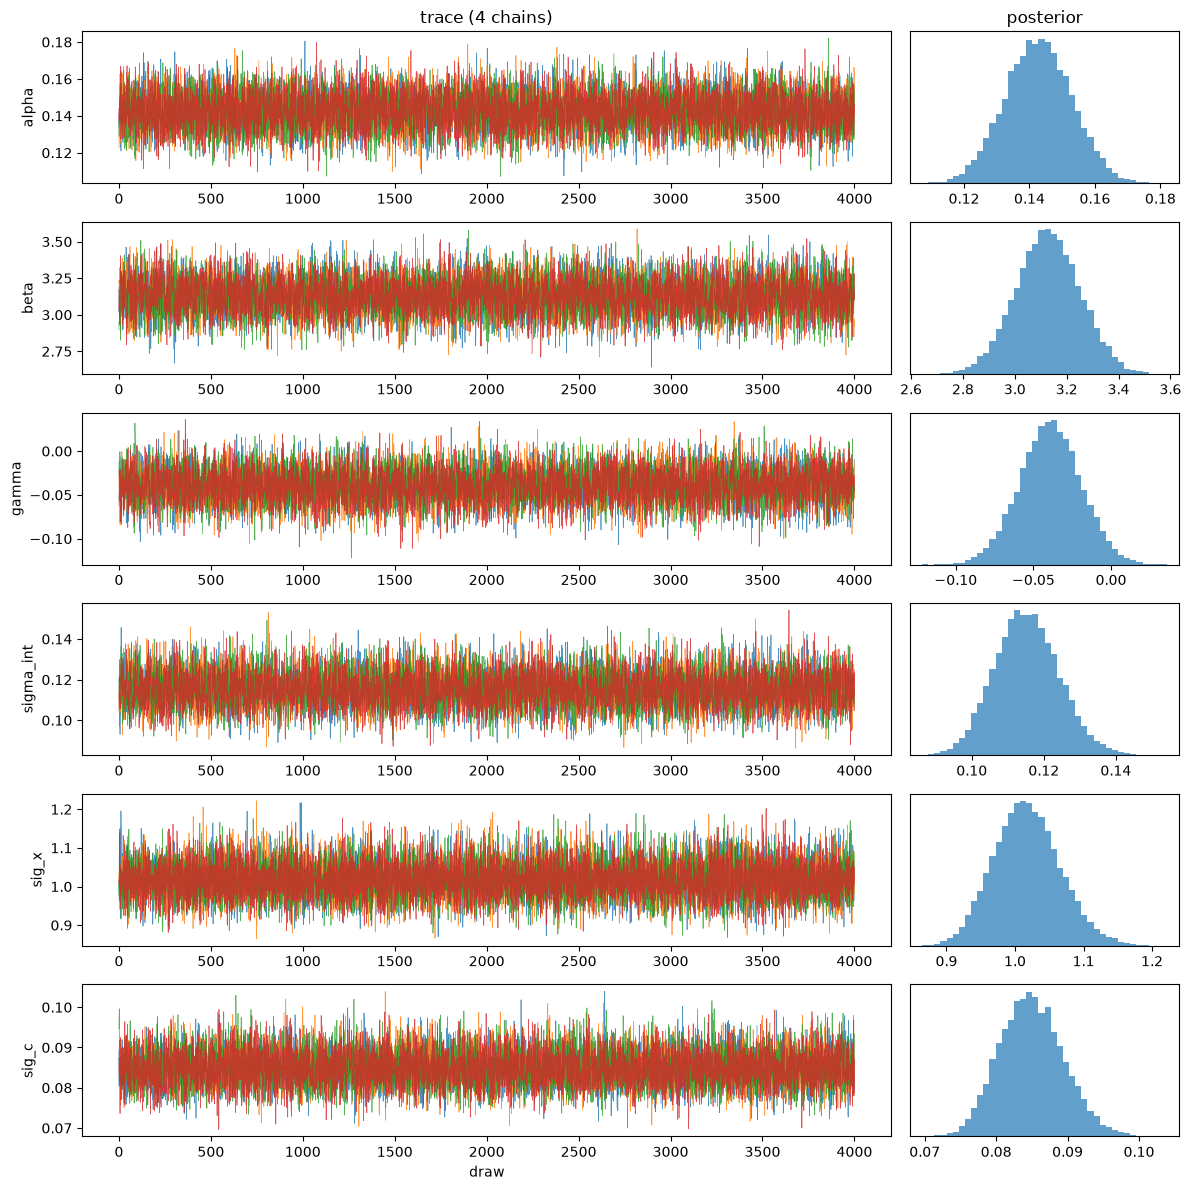

lowest-ESS parameters:
           r_hat ess_bulk
lnsig      1.00     9756
sigma_int  1.00     9756
gamma      1.00    10330
beta       1.00    10506
M          1.00    10986


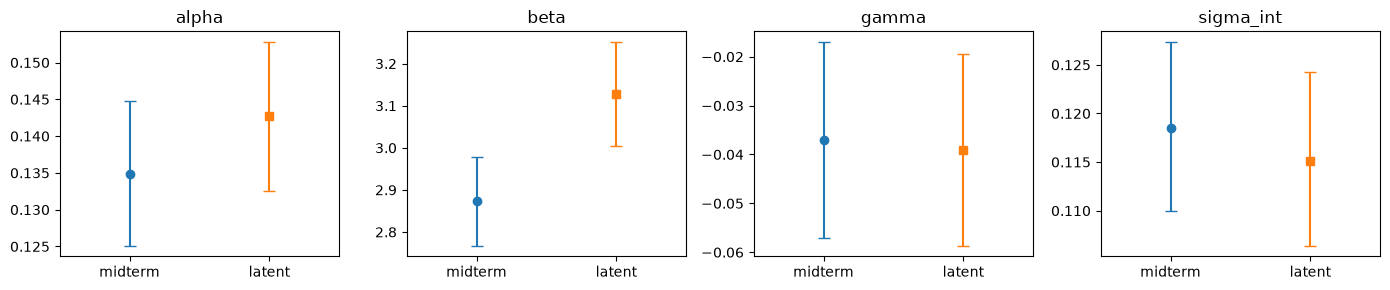

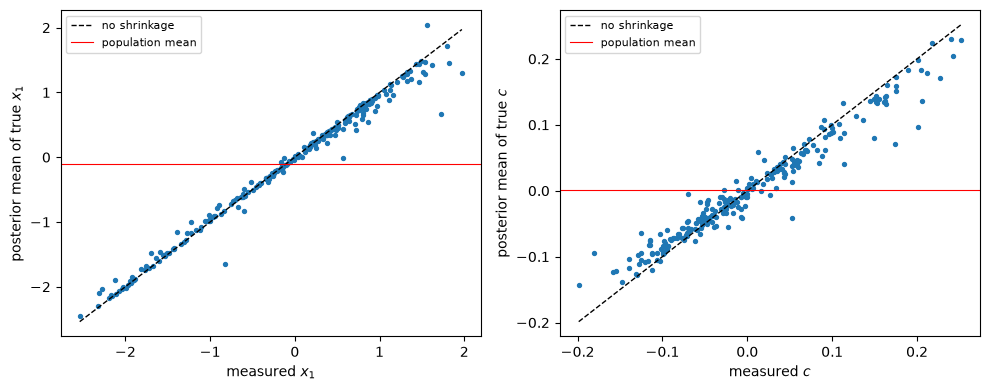

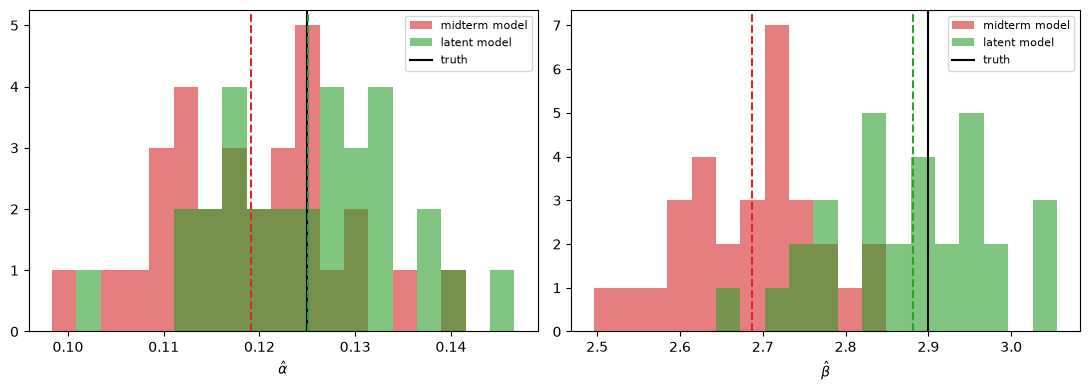

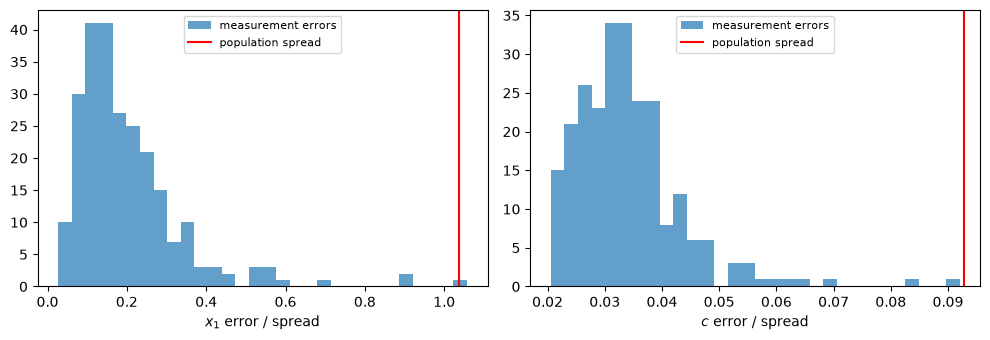

Median measurement error / population spread:
x1: 0.160
c: 0.355


In [6]:
# a bunch of plots added for analysis after the main computations

names = ['alpha', 'beta', 'gamma', 'sigma_int', 'sig_x', 'sig_c']
fig, ax = plt.subplots(len(names), 2, figsize=(12, 2*len(names)), gridspec_kw={'width_ratios': [3, 1]})
for i, nm in enumerate(names):
    v = idata.posterior[nm].values                       # (chain, draw)
    for ch in range(v.shape[0]):
        ax[i, 0].plot(v[ch], lw=0.5, alpha=0.8)
    ax[i, 1].hist(v.ravel(), bins=40, color='C0', alpha=0.7)
    ax[i, 0].set_ylabel(nm)
    ax[i, 1].set_yticks([])
ax[0, 0].set_title('trace (4 chains)'); ax[0, 1].set_title('posterior')
ax[-1, 0].set_xlabel('draw')
plt.tight_layout(); plt.show()

# worst-mixing latent values
ess = summ['ess_bulk']
print("lowest-ESS parameters:\n", summ.loc[ess.nsmallest(5).index, ['r_hat', 'ess_bulk']].round(3))

# (value, +err, -err) from your midterm 2c
mid_vals = {'alpha': (0.1349, 0.0099, 0.0098), 'beta': (2.8739, 0.1049, 0.1065),
            'gamma': (-0.0370, 0.0201, 0.0200), 'sigma_int': (0.1185, 0.0089, 0.0085)}

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, (nm, (m, hi, lo)) in zip(ax, mid_vals.items()):
    lo2, med2, hi2 = np.percentile(idata.posterior[nm].values.ravel(), [16, 50, 84])
    a.errorbar([0], [m], yerr=[[lo], [hi]], fmt='o', capsize=4, label='midterm')
    a.errorbar([1], [med2], yerr=[[med2-lo2], [hi2-med2]], fmt='s', capsize=4, label='latent model')
    a.set_xticks([0, 1]); a.set_xticklabels(['midterm', 'latent']); a.set_xlim(-0.5, 1.5)
    a.set_title(nm)
plt.tight_layout(); plt.show()

# shrinkage: posterior mean of the true values vs the measured values
x1_pm = idata.posterior['x1_true'].values.mean(axis=(0, 1))
c_pm  = idata.posterior['c_true'].values.mean(axis=(0, 1))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, obs, pm_, nm, mu_pop in [(ax[0], x1, x1_pm, r'$x_1$', idata.posterior['mu_x'].values.mean()),
                                (ax[1], c, c_pm, r'$c$', idata.posterior['mu_c'].values.mean())]:
    a.scatter(obs, pm_, s=8)
    lim = np.array([obs.min(), obs.max()])
    a.plot(lim, lim, 'k--', lw=1, label='no shrinkage')
    a.axhline(mu_pop, color='r', lw=0.8, label='population mean')
    a.set_xlabel(f'measured {nm}'); a.set_ylabel(f'posterior mean of true {nm}')
    a.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, idx, nm, true in [(ax[0], 1, r'$\hat\alpha$', TRUE['alpha']), (ax[1], 2, r'$\hat\beta$', TRUE['beta'])]:
    lo = min(est_mid[:, idx].min(), est_lat[:, idx].min()); hi = max(est_mid[:, idx].max(), est_lat[:, idx].max())
    bins = np.linspace(lo, hi, 20)
    a.hist(est_mid[:, idx], bins=bins, alpha=0.6, color='C3', label='midterm model')
    a.hist(est_lat[:, idx], bins=bins, alpha=0.6, color='C2', label='latent model')
    a.axvline(true, color='k', lw=1.5, label='truth')
    a.axvline(est_mid[:, idx].mean(), color='C3', ls='--')
    a.axvline(est_lat[:, idx].mean(), color='C2', ls='--')
    a.set_xlabel(nm); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

# measurement error vs population spread: the source of the attenuation
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, spread, err, nm in [(ax[0], x1.std(), np.sqrt(C[:, 1, 1]), r'$x_1$'),
                           (ax[1], c.std(),  np.sqrt(C[:, 2, 2]), r'$c$')]:
    a.hist(err, bins=30, color='C0', alpha=0.7, label='measurement errors')
    a.axvline(spread, color='r', label='population spread')
    a.set_xlabel(f'{nm} error / spread'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Median measurement error / population spread:")
print(f"x1: {np.median(np.sqrt(C[:, 1, 1])) / x1.std():.3f}")
print(f"c: {np.median(np.sqrt(C[:, 2, 2])) / c.std():.3f}")

**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

1. Before: <img src="1_Before.png" alt="The probabilistic graphical model for the midterm problem's original (incorrect) model" style="display:block;margin:15px auto;max-height:400px;max-width:100%"> After: <img src="1_After.png" alt="The probabilistic graphical model for the midterm problem's corrected model" style="display:block;margin:15px auto;max-height:400px;max-width:100%"> The issues were not fitting/including the population $\mu,\sigma$ values for drawing $x_{1,i},c_i$, missing the arrows from true $x_{1,i},c_i$ to the measured $\hat{x}_{1,i},\hat{c}_i,\hat{m}_{B,i}$, and not feeding $C_i$ into the observables $\hat{c}_i,\hat{m}_{B,i}$. The circles that should have been white were $x_{1,i},c_i$, though the midterm used the grey $\hat{x}_{1,i},\hat{c}_i$ values instead. (Aside: Apologies for not having proper latex symbols, I figured an electronic version would be easier to read as I could color and model it accurately, but I couldn't find a way to insert latex in the website I used, app.diagrams.net).
2. As in the midterm, I handled contaminants via iterative clipping, removing the 4 points that were very clearly contaminants based on my midterm analysis. I chose centered for this dataset as we can see in the last plot that the errors are significantly smaller than the population spread (the lecture recommends centered in such a case), and we also don't have any issues with divergence so centering lets us keep more effective data. Largest R hat was $\hat{R}=1.002$, well within the allowed $\hat{R}<1.01$ restriction. The lowest effective sample size was $9756$, there were 0 divergences, and the obtained values were $\alpha=0.1427^{+0.0101}_{-0.0102}$, $\beta=3.1283^{+0.1243}_{-0.1237}$, $\gamma=-0.0391^{+0.0197}_{-0.0196}$, and $\sigma_{int}=0.1151^{+0.0091}_{-0.0087}$.
3. The results were as follows: for the midterm model, $\alpha=0.1192 \pm 0.0017$ (true 0.125) and $\beta=2.6869 \pm 0.0152$ (true 2.9). This problem's solution has $\alpha=0.1251 \pm 0.0018$ and $\beta=2.8811 \pm 0.0176$. The reason the midterm got it wrong was just regression dilution, the same effect we saw in class where the least squares regression was biased low because there were x-errors which hadn't been accounted for (at least in the regressor, it accounted for it only in the variance). It's the same here, except we have multiple different independent variables so it's biased low when plotted against both axes ($x_1$ and $c$). The $\beta$ value is more heavily biased as the median measurement error for the corresponding independent variable $c$ is a significantly higher fraction of the population spread, and again as mentioned in class this bias effect becomes harsher the higher your x error becomes relative to your population's spread. The latent model here avoids the bias because we've built it to account for the populations of $x_{1}$ and $c$ values from the start, so the fact that we do have scatters there is expected and doesn't bias the results one way or the other.

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a $4\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?

5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

Total detected sources in catalog: 1500
Count range: min = 33, max = 3000
F_half (detected 50% of the time): 0.10295 F_0 (expected counts: 32.67)


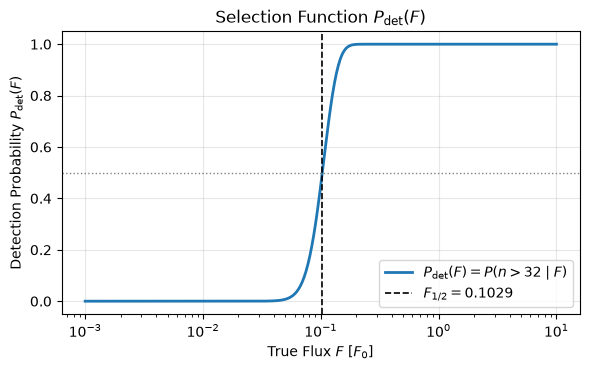

In [7]:
# Part 2: your work here
# ==============================================================================
# Setup, Saturation Check, and Selection Function
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, optimize

# --- Load data and survey parameters ---
n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu = 9.373          # background sky + detector counts
eps = 226.27        # exposure (counts per unit reference flux F0)
n_th = 32           # detection threshold (strict: n > 32 -> n >= 33)
N_det = len(n)

print(f"Total detected sources in catalog: {N_det}")
print(f"Count range: min = {n.min()}, max = {n.max()}")

# --- Detection Probability P_det(F) ---
def P_det(F):
    lam = eps * F + nu
    # P(n > 32 | F) = P(n >= 33 | F) = gammainc(33, lam)
    return special.gammainc(33.0, lam)

# Check against scipy.stats.poisson.sf
test_F = np.array([0.01, 0.05, 0.1, 0.2, 0.5])
assert np.allclose(stats.poisson.sf(n_th, eps * test_F + nu), P_det(test_F), atol=1e-12)

# Flux detected half the time
F_half = optimize.root_scalar(lambda F: P_det(F) - 0.5, bracket=[0.001, 1.0]).root
print(f"F_half (detected 50% of the time): {F_half:.5f} F_0 (expected counts: {eps*F_half + nu:.2f})")

# Plot P_det(F)
fig, ax = plt.subplots(figsize=(6, 3.8))
F_plot = np.logspace(-3, 1, 500)
ax.plot(F_plot, P_det(F_plot), 'C0-', lw=2, label=r'$P_{\rm det}(F) = P(n > 32 \mid F)$')
ax.axvline(F_half, color='k', ls='--', lw=1.2, label=f'$F_{{1/2}} = {F_half:.4f}$')
ax.axhline(0.5, color='gray', ls=':', lw=1)
ax.set_xscale('log')
ax.set_xlabel(r'True Flux $F$ [$F_0$]')
ax.set_ylabel(r'Detection Probability $P_{\rm det}(F)$')
ax.set_title(r'Selection Function $P_{\rm det}(F)$')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

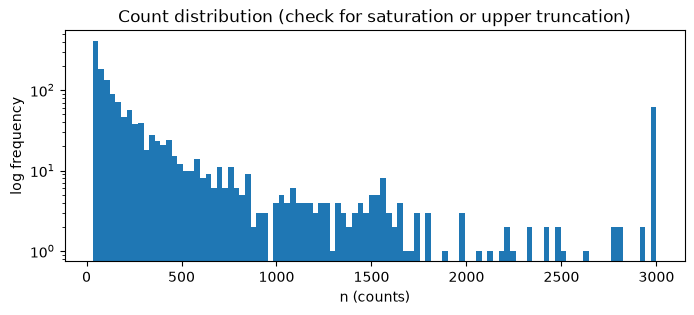

Sources with n >= 2900: 63
Sources with n == 3000: 59


In [8]:
# Saturation identification
is_sat = (n == 3000)
n_sat = np.sum(is_sat)

plt.figure(figsize=(8, 3))
plt.hist(n, bins=100)
plt.yscale('log')
plt.xlabel('n (counts)')
plt.ylabel('log frequency')
plt.title('Count distribution (check for saturation or upper truncation)')
plt.show()

print("Sources with n >= 2900:", np.sum(n >= 2900))
print("Sources with n == 3000:", n_sat)

In [9]:
# ==============================================================================
# Likelihood Integration on Grid: Raw vs. Truncation vs. Censoring
# ==============================================================================
d_lnF = 0.01
lnF_grid = np.arange(-14.0, 8.0 + d_lnF, d_lnF)
F_grid = np.exp(lnF_grid)
lam_grid = eps * F_grid + nu
log_lam = np.log(lam_grid)
pdet_grid = P_det(F_grid)

# --- Precompute Likelihood Matrices ---
# 1. Raw exact Poisson for all 1500 points
log_poiss_all = n[:, None] * log_lam[None, :] - lam_grid[None, :] - special.gammaln(n[:, None] + 1.0)

# 2. Truncated sample (discarding n == 3000)
n_trunc = n[~is_sat]
log_poiss_trunc = n_trunc[:, None] * log_lam[None, :] - lam_grid[None, :] - special.gammaln(n_trunc[:, None] + 1.0)
pdet_trunc_grid = special.gammainc(33.0, lam_grid) - special.gammainc(3000.0, lam_grid)

# 3. Censored sample (n < 3000 exact Poisson; n == 3000 cumulative P(n >= 3000))
p_sat_grid = special.gammainc(3000.0, lam_grid)
log_p_sat_grid = np.log(np.maximum(p_sat_grid, 1e-300))

log_like_cens = np.zeros((N_det, len(lnF_grid)))
log_like_cens[~is_sat, :] = log_poiss_all[~is_sat, :]
log_like_cens[is_sat, :] = log_p_sat_grid[None, :]

# --- Likelihood Functions Generator ---
def make_nll(like_mat, pdet_vec=None, N_sample=N_det):
    def nll(params):
        mu, sig = params
        if sig <= 0:
            return 1e12
        log_p_lnF = -0.5 * ((lnF_grid - mu) / sig)**2 - np.log(sig * np.sqrt(2 * np.pi))
        log_p_ni = special.logsumexp(like_mat + log_p_lnF[None, :], axis=1) + np.log(d_lnF)
        val = -np.sum(log_p_ni)
        if pdet_vec is not None:
            f_det = np.sum(pdet_vec * np.exp(log_p_lnF)) * d_lnF
            if f_det <= 1e-15:
                return 1e12
            val += N_sample * np.log(f_det)
        return val
    return nll

# Instantiate negative log likelihoods
nll_naive_raw   = make_nll(log_poiss_all, pdet_vec=None)
nll_corr_raw    = make_nll(log_poiss_all, pdet_vec=pdet_grid)

nll_naive_trunc = make_nll(log_poiss_trunc, pdet_vec=None)
nll_corr_trunc  = make_nll(log_poiss_trunc, pdet_vec=pdet_trunc_grid, N_sample=len(n_trunc))

nll_naive_cens  = make_nll(log_like_cens, pdet_vec=None)
nll_corr_cens   = make_nll(log_like_cens, pdet_vec=pdet_grid)

# Hessian error estimator
def get_errors(nll_func, opt_x):
    h = 1e-4
    H = np.zeros((2, 2))
    for i in range(2):
        for j in range(2):
            p_pp, p_pm, p_mp, p_mm = opt_x.copy(), opt_x.copy(), opt_x.copy(), opt_x.copy()
            p_pp[i] += h; p_pp[j] += h
            p_pm[i] += h; p_pm[j] -= h
            p_mp[i] -= h; p_mp[j] += h
            p_mm[i] -= h; p_mm[j] -= h
            H[i, j] = (nll_func(p_pp) - nll_func(p_pm) - nll_func(p_mp) + nll_func(p_mm)) / (4 * h * h)
    return np.sqrt(np.diag(np.linalg.inv(H)))

# Optimize all fits
p0 = [-0.4, 1.3]
bounds = [(-5, 2), (0.1, 4.0)]

fits = {}
models = [
    ('Raw Data (naive)', nll_naive_raw, None, N_det),
    ('Raw Data (corrected)', nll_corr_raw, pdet_grid, N_det),
    ('Truncated (naive)', nll_naive_trunc, None, len(n_trunc)),
    ('Truncated (corrected)', nll_corr_trunc, pdet_trunc_grid, len(n_trunc)),
    ('Censored (naive)', nll_naive_cens, None, N_det),
    ('Censored (corrected)', nll_corr_cens, pdet_grid, N_det)
]

for name, nll_func, pdet_vec, N_samp in models:
    res = optimize.minimize(nll_func, p0, method='L-BFGS-B', bounds=bounds)
    err = get_errors(nll_func, res.x)
    mu_fit, sig_fit = res.x
    if pdet_vec is not None:
        log_p = -0.5 * ((lnF_grid - mu_fit) / sig_fit)**2 - np.log(sig_fit * np.sqrt(2 * np.pi))
        f_det = np.sum(pdet_vec * np.exp(log_p)) * d_lnF
        N_tot = N_samp / f_det
        N_miss = N_tot - N_samp
    else:
        f_det, N_tot, N_miss = np.nan, np.nan, np.nan
    fits[name] = {'mu': mu_fit, 'mu_err': err[0], 'sig': sig_fit, 'sig_err': err[1],
                  'f_det': f_det, 'N_tot': N_tot, 'N_miss': N_miss}

# Display Clean Comparison Table
comp_table = pd.DataFrame({
    'Model Treatment': list(fits.keys()),
    'mu': [f"{v['mu']:.4f} +/- {v['mu_err']:.4f}" for v in fits.values()],
    'sigma': [f"{v['sig']:.4f} +/- {v['sig_err']:.4f}" for v in fits.values()],
    'f_det': [f"{v['f_det']:.4f}" if not np.isnan(v['f_det']) else '---' for v in fits.values()],
    'Estimated Missed Sources': [f"{v['N_miss']:.1f}" if not np.isnan(v['N_miss']) else '---' for v in fits.values()]
})
display(comp_table)

,Model Treatment,mu,sigma,f_det,Estimated Missed Sources
0,Raw Data (naive),-0.3990 +/- 0.0346,1.3333 +/- 0.0246,---,---
1,Raw Data (corrected),-1.5254 +/- 0.1598,1.9728 +/- 0.0833,0.6496,809.0
2,Truncated (naive),-0.5201 +/- 0.0321,1.2117 +/- 0.0228,---,---
3,Truncated (corrected),-2.0263 +/- 0.3386,2.2900 +/- 0.2013,0.5234,1312.1
4,Censored (naive),-0.3801 +/- 0.0359,1.3830 +/- 0.0263,---,---
5,Censored (corrected),-2.0010 +/- 0.2548,2.2712 +/- 0.1199,0.5503,1225.9


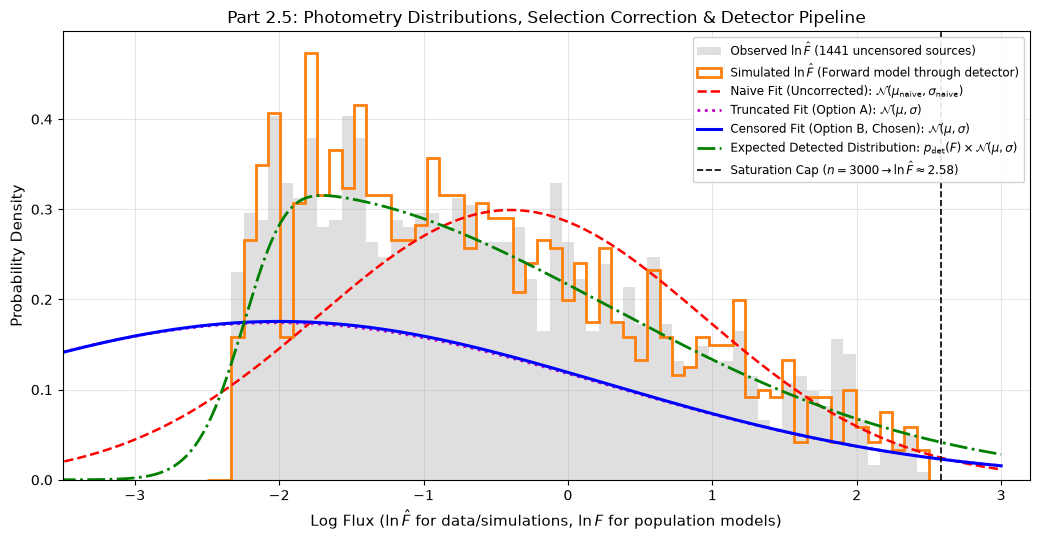

In [10]:
# ==============================================================================
# Final Diagnostic Plot: Distributions, Selection, and Pipeline Check
# ==============================================================================
# Extract parameters from the chosen model (Option B: Censored + Corrected)
mu_best = fits['Censored (corrected)']['mu']
sig_best = fits['Censored (corrected)']['sig']
f_det_best = fits['Censored (corrected)']['f_det']

# Defined explicitly here:
N_tot_cens = fits['Censored (corrected)']['N_tot']
N_tot_best = int(np.round(N_tot_cens))

# Observed ln(F_hat) for uncensored data (n < 3000)
lnF_hat_obs = np.log((n[~is_sat] - nu) / eps)

# Forward simulation through the actual pipeline
rng = np.random.default_rng(2026)
sim_true_lnF = rng.normal(mu_best, sig_best, size=N_tot_best)
sim_counts_raw = rng.poisson(eps * np.exp(sim_true_lnF) + nu)

# Detector threshold (n > 32) and saturation cap (min(n, 3000))
sim_detected = sim_counts_raw > n_th
sim_counts_detected = np.minimum(sim_counts_raw[sim_detected], 3000)
sim_lnF_hat = np.log((sim_counts_detected[sim_counts_detected < 3000] - nu) / eps)

# Setup Figure
fig, ax = plt.subplots(figsize=(10.5, 5.5))
bins = np.linspace(-2.5, 2.5, 60)

# 1. Observed catalog distribution
ax.hist(lnF_hat_obs, bins=bins, density=True, histtype='stepfilled',
        alpha=0.25, color='gray', label=f'Observed $\\ln\\hat{{F}}$ ({len(lnF_hat_obs)} uncensored sources)')

# 2. Forward simulated distribution through detector pipeline
ax.hist(sim_lnF_hat, bins=bins, density=True, histtype='step', lw=2,
        color='C1', label='Simulated $\\ln\\hat{{F}}$ (Forward model through detector)')

# 3. Analytic population & selection curves
lnF_axis = np.linspace(-4, 3, 500)
ax.plot(lnF_axis, stats.norm.pdf(lnF_axis, fits['Raw Data (naive)']['mu'], fits['Raw Data (naive)']['sig']),
        'r--', lw=1.8, label=r'Naive Fit (Uncorrected): $\mathcal{N}(\mu_{\rm naive}, \sigma_{\rm naive})$')
ax.plot(lnF_axis, stats.norm.pdf(lnF_axis, fits['Truncated (corrected)']['mu'], fits['Truncated (corrected)']['sig']),
        'm:', lw=2.0, label=r'Truncated Fit (Option A): $\mathcal{N}(\mu, \sigma)$')
ax.plot(lnF_axis, stats.norm.pdf(lnF_axis, mu_best, sig_best),
        'b-', lw=2.2, label=r'Censored Fit (Option B, Chosen): $\mathcal{N}(\mu, \sigma)$')
ax.plot(lnF_axis, (P_det(np.exp(lnF_axis)) * stats.norm.pdf(lnF_axis, mu_best, sig_best)) / f_det_best,
        'g-.', lw=2.0, label=r'Expected Detected Distribution: $p_{\rm det}(F) \times \mathcal{N}(\mu, \sigma)$')

# Saturation line
ax.axvline(np.log((3000 - nu) / eps), color='black', ls='--', lw=1.2,
           label=r'Saturation Cap ($n = 3000 \rightarrow \ln\hat{F} \approx 2.58$)')

ax.set_xlim(-3.5, 3.2)
ax.set_xlabel(r'Log Flux ($\ln\hat{F}$ for data/simulations, $\ln F$ for population models)', fontsize=11)
ax.set_ylabel('Probability Density', fontsize=11)
ax.set_title(r'Part 2.5: Photometry Distributions, Selection Correction & Detector Pipeline', fontsize=12)
ax.legend(loc='upper right', fontsize=8.5, framealpha=0.9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**ANSWER (the two fits, f_det and the number missed, then the explanation):**

1. The main thing I found was my survey data didn't just have a lower threshold, but an upper bound on the tracked counts (3000 to be precise, with 59/1500 points at that limit). Essentially right-censoring, as the data with sufficiently high flux all got binned together which would impact the mean and deviation we recieve from a more naive fit. To fix this I could have just trimmed the data, but that would artificially decrease the mean as shown above, so I decided to treat it as we did the lower bound: model their probability as the Poisson survival probability $P(n \ge 3000 \mid F) = \text{gammainc}(3000, \epsilon F + \nu)$. This lets us keep all the data points while not biasing the fitted mean as much as truncating the data would have, and we also obtain tighter error bars. You can see how the fix compares to truncation and ignoring the problem in the plot and table above.
2. The sampling distribution of $n$ given $F$ is just the Poisson distribution $\operatorname{Poisson}(\epsilon F+\nu)$. The detection probability is given by $P_{\rm det}(F) = P(n > 32 \mid F) = \text{gammainc}(33, \epsilon F + \nu)$ and the flux at which we expect 50% detection is $F=0.10295 F_0.$
3. Latent values are $F_i$ and $N$, fitted values are $\mu,\sigma,$ fixed/known values are $\nu, \epsilon, n_{th},$ and observed values are $n_i, I_i,$ and $N_{det}$ (note that $n_I$ and $I_i$ are only truly detected if the counts surpass the threshold, otherwise they stay hidden). $N$ and $N_{det}$ stay outside the plate as they are not found for individual supernovae but for the whole dataset. <img src="2.3.png" alt="The probabilistic graphical model for this problem" style="display:block;margin:15px auto;max-height:400px;max-width:100%"> 
4. I obtained $\mu=-2.0010 \pm 0.2548$ and $\sigma=2.2712 \pm 0.1199$ (errors from Hessian curvature) with $f_{det}=0.5503\Rightarrow 1225.9$ estimated missed sources.
5. The histogram of synthetic detected data matches the observed data closely enough that I believe the simulation is working properly. However, looking at the expected distribution given by multiplying $p_{det}$ by our corrected population, we see that at low log flux values both the observed and simulated values are significantly above the expected distribution. I expect this is caused by Eddington bias; since we have a lot more sources which are at the lower bound of our detection limit than ones at the higher bound, we expect to see relatively more data points which happen to be scattered above the required measurement threshold for detection simply due to measurement noise. This should result in more actual detections than predicted at the lower end which is exactly what we see.

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

In [11]:
# Part 3: your work here
asg = pd.read_csv(LAB + 'csp_assignments.csv')
SN, HOLD = asg.loc[asg.netid == NETID, ['sn', 'holdout_band']].iloc[0]
path = LAB + f'csp/{SN}.csv'
hdr = [l for l in open(path) if l.startswith('#')]          # the header lines: source, license, redshift, date of B maximum
z = float([l for l in hdr if 'z_helio' in l][0].split(':')[-1])
tmax = float([l for l in hdr if 'B-max MJD' in l][0].split(':')[1].split('+/-')[0])
d = pd.read_csv(path, comment='#')
d['band'] = d['band'].replace({'V0': 'V', 'V1': 'V'})   # V0, V1 and V are the same filter - treat them as one band
print(f'{SN}: z = {z}, B maximum at MJD {tmax}, {len(d)} points; held-out band: {HOLD}')

SN2004eo: z = 0.0157, B maximum at MJD 53278.24, 221 points; held-out band: V


Peak B-band flux used for normalization: 2587.00 uJy


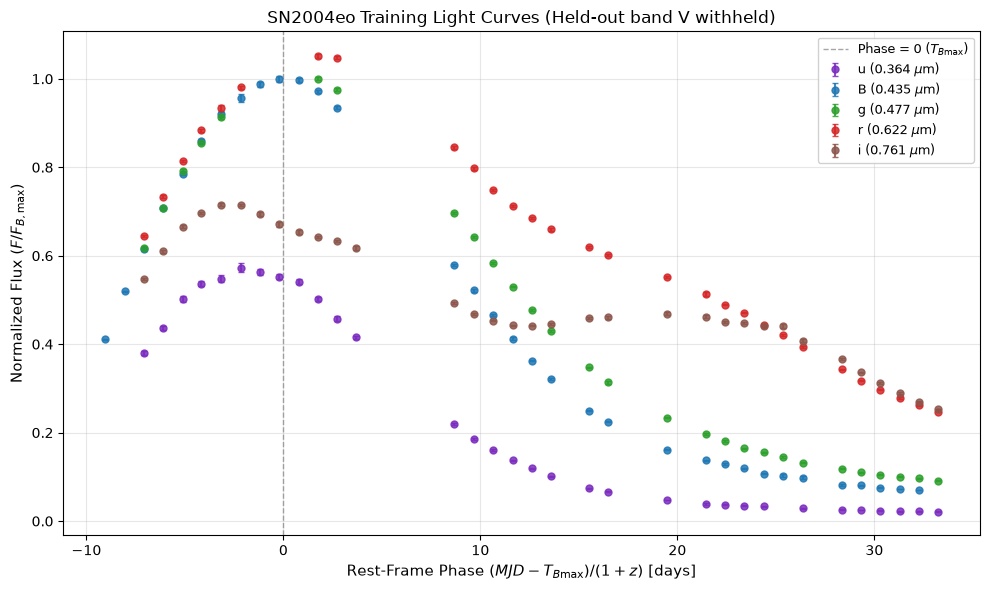

Fitting 2D GP on 155 points across bands: ['u', 'B', 'g', 'r', 'i']...

--- Optimized GP Hyperparameters ---
Phase length scale   (l_phase)   : 6.978 days
Wavelength scale     (l_wave)    : 0.1208 microns (1207.8 Angstroms)
Kernel amplitude     (sigma_f^2) : 0.1032
Additional white noise           : 2.16e-15
Log marginal likelihood          : 518.08


In [12]:
# ==============================================================================
# Preprocessing, Kept-Bands Plot, and 2D GP Fit (sklearn)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

# --- Data Preparation & Normalization ---
# Compute rest-frame phase in days
d['phase'] = (d['mjd'] - tmax) / (1.0 + z)

# Restrict to phase in [-10, +40] days as specified
mask_phase = (d['phase'] >= -10.0) & (d['phase'] <= 40.0)
df = d[mask_phase].copy().reset_index(drop=True)

# Convert wavelength from Angstroms to microns (order 1-50)
df['wave_um'] = df['wavelength_A'] / 10000.0

# Find peak B flux for normalization
b_mask = df['band'] == 'B'
b_flux_peak = df.loc[b_mask, 'flux_ujy'].max() if b_mask.any() else d.loc[d['band'] == 'B', 'flux_ujy'].max()
print(f"Peak B-band flux used for normalization: {b_flux_peak:.2f} uJy")

# Normalize flux and flux error by peak B flux
df['flux_norm'] = df['flux_ujy'] / b_flux_peak
df['flux_err_norm'] = df['flux_err_ujy'] / b_flux_peak

# Separate training data: strictly EXCLUDE the held-out band (HOLD)
train_df = df[df['band'] != HOLD].copy().reset_index(drop=True)

# ==============================================================================
# Plot every kept band against phase (EXCLUDING held-out band)
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 6))

band_colors = {
    'u': '#7b2cbf', 
    'B': '#1f77b4', 
    'g': '#2ca02c', 
    'V': '#e377c2', 
    'r': '#d62728', 
    'i': '#8c564b'
}

# Only include the training bands (held-out band is excluded)
train_bands = [b for b in ['u', 'B', 'g', 'r', 'i'] if b in train_df['band'].unique()]

for b in train_bands:
    b_df = train_df[train_df['band'] == b].sort_values('phase')
    wave_val = b_df['wave_um'].iloc[0]
    
    ax.errorbar(
        b_df['phase'], b_df['flux_norm'], yerr=b_df['flux_err_norm'],
        fmt='o',
        color=band_colors.get(b, 'black'),
        ms=5,
        capsize=2.5,
        alpha=0.85,
        label=f"{b} ({wave_val:.3f} $\\mu$m)"
    )

ax.set_xlabel(r'Rest-Frame Phase $(MJD - T_{B{\rm max}}) / (1+z)$ [days]', fontsize=11)
ax.set_ylabel(r'Normalized Flux ($F / F_{B,{\rm max}}$)', fontsize=11)
ax.set_title(f'{SN} Training Light Curves (Held-out band {HOLD} withheld)', fontsize=12)
ax.axvline(0, color='gray', ls='--', lw=1, alpha=0.7, label=r'Phase = 0 ($T_{B\rm max}$)')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=9, framealpha=0.9)
plt.tight_layout()
plt.show()

# ==============================================================================
# Fit 2D GP (phase, wavelength) with sklearn
# ==============================================================================
X_train = train_df[['phase', 'wave_um']].to_numpy()
y_train = train_df['flux_norm'].to_numpy()
y_err_train = train_df['flux_err_norm'].to_numpy()

# Anisotropic RBF with ConstantKernel amplitude + WhiteKernel noise
kernel = (
    ConstantKernel(constant_value=1.0, constant_value_bounds=(0.1, 10.0))
    * RBF(length_scale=[15.0, 0.15], length_scale_bounds=[(1.0, 60.0), (0.01, 2.0)])
    + WhiteKernel(noise_level=1e-4, noise_level_bounds=(1e-16, 1e-1))
)

# alpha = squared errors; normalize_y=False as instructed
gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=y_err_train**2,
    normalize_y=False,
    n_restarts_optimizer=10,
    random_state=2026
)

print(f"Fitting 2D GP on {len(X_train)} points across bands: {train_bands}...")
gp.fit(X_train, y_train)

# Extract fitted hyperparameters
opt_kernel = gp.kernel_
l_phase, l_wave = opt_kernel.k1.k2.length_scale
amp = opt_kernel.k1.k1.constant_value
white_noise = opt_kernel.k2.noise_level

print("\n--- Optimized GP Hyperparameters ---")
print(f"Phase length scale   (l_phase)   : {l_phase:.3f} days")
print(f"Wavelength scale     (l_wave)    : {l_wave:.4f} microns ({l_wave * 10000.0:.1f} Angstroms)")
print(f"Kernel amplitude     (sigma_f^2) : {amp:.4f}")
print(f"Additional white noise           : {white_noise:.2e}")
print(f"Log marginal likelihood          : {gp.log_marginal_likelihood(gp.kernel_.theta):.2f}")

--- Held-out Band (V) Performance Metrics ---
RMS residual: 0.0238
RMS as fraction of peak: 2.45% (peak = 0.969)
Fraction of points within 1-sigma: 41.2% (14 / 34 points)


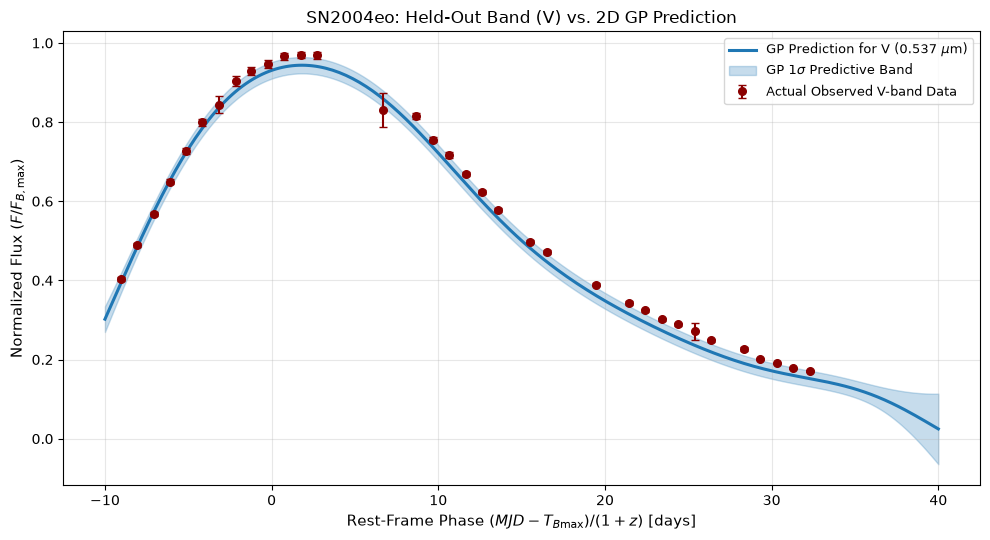

In [13]:
# ==============================================================================
# Predict Held-Out Band (V), Plot, and Quantify Residuals
# ==============================================================================
# 1. Extract the held-out band data
hold_df = df[df['band'] == HOLD].sort_values('phase').copy().reset_index(drop=True)
X_hold = hold_df[['phase', 'wave_um']].to_numpy()
y_hold = hold_df['flux_norm'].to_numpy()
y_err_hold = hold_df['flux_err_norm'].to_numpy()
wave_hold = hold_df['wave_um'].iloc[0]

# 2. Predict at the exact observed epochs
y_pred_pts, std_gp_pts = gp.predict(X_hold, return_std=True)

# Total 1-sigma uncertainty: add GP variance and measurement variance
sigma_tot_pts = np.sqrt(std_gp_pts**2 + y_err_hold**2)

# Residuals and metrics
residuals = y_hold - y_pred_pts
rms = np.sqrt(np.mean(residuals**2))
peak_hold = y_hold.max()
fractional_rms = rms / peak_hold

# Fraction within 1 sigma
inside_1sig = np.abs(residuals) <= sigma_tot_pts
fraction_1sig = np.mean(inside_1sig)

print(f"--- Held-out Band ({HOLD}) Performance Metrics ---")
print(f"RMS residual: {rms:.4f}")
print(f"RMS as fraction of peak: {fractional_rms*100:.2f}% (peak = {peak_hold:.3f})")
print(f"Fraction of points within 1-sigma: {fraction_1sig*100:.1f}% ({inside_1sig.sum()} / {len(y_hold)} points)")

# 3. Dense grid for smooth GP curve plotting
phase_grid = np.linspace(-10.0, 40.0, 250)
X_grid = np.column_stack([phase_grid, np.full_like(phase_grid, wave_hold)])
y_pred_grid, std_gp_grid = gp.predict(X_grid, return_std=True)

# 4. Plot
fig, ax = plt.subplots(figsize=(10, 5.5))

# Plot GP mean prediction and 1-sigma model band
ax.plot(phase_grid, y_pred_grid, color='C0', lw=2.2, label=f'GP Prediction for {HOLD} ({wave_hold:.3f} $\\mu$m)')
ax.fill_between(
    phase_grid,
    y_pred_grid - std_gp_grid,
    y_pred_grid + std_gp_grid,
    color='C0', alpha=0.25, label=r'GP $1\sigma$ Predictive Band'
)

# Plot actual held-out observations
ax.errorbar(
    hold_df['phase'], y_hold, yerr=y_err_hold,
    fmt='o', color='darkred', ecolor='darkred', ms=5.5, capsize=3,
    label=f'Actual Observed {HOLD}-band Data'
)

ax.set_xlabel(r'Rest-Frame Phase $(MJD - T_{B{\rm max}}) / (1+z)$ [days]', fontsize=11)
ax.set_ylabel(r'Normalized Flux ($F / F_{B,{\rm max}}$)', fontsize=11)
ax.set_title(f'{SN}: Held-Out Band ({HOLD}) vs. 2D GP Prediction', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=9.5)
plt.tight_layout()
plt.show()

Refitting 2D GP holding out 'u' (0.364 um) across training bands: ['B', 'V', 'g', 'r', 'i']...
Fitted length scales: l_phase = 6.859 days, l_wave = 0.1359 um (1358.7 A)

--- Held-out Band (u) Performance Metrics ---
RMS residual                  : 0.1127
RMS as fraction of peak       : 19.67% (peak = 0.573)
Fraction of points within 1-sig: 0.0% (0 / 32 points)


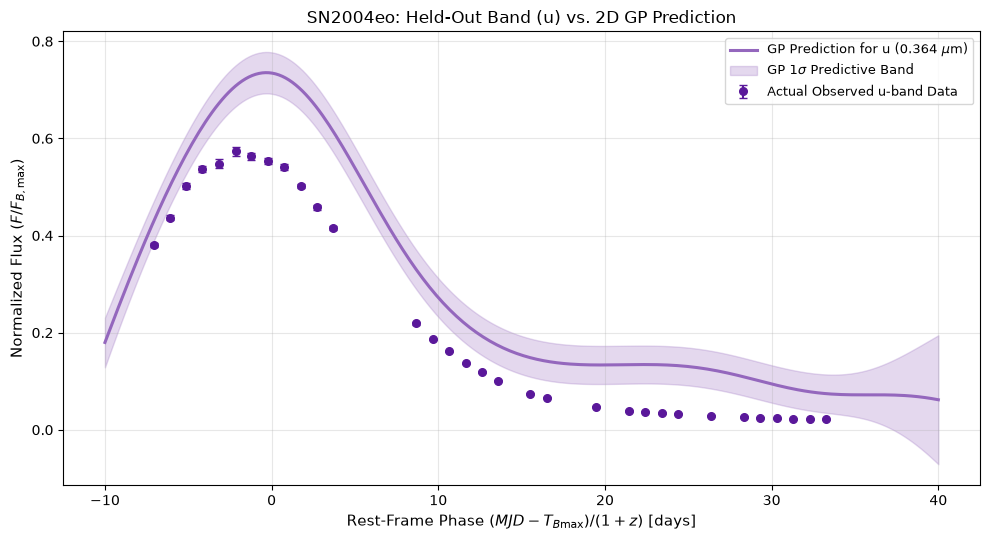

In [14]:
# ==============================================================================
# Hold out 'u' instead, refit 2D GP, report metrics, and plot
# ==============================================================================
HOLD_U = 'u'

# 1. Prepare new training and hold-out datasets (now including V in training!)
train_df_u = df[df['band'] != HOLD_U].copy().reset_index(drop=True)
hold_df_u  = df[df['band'] == HOLD_U].sort_values('phase').copy().reset_index(drop=True)

X_train_u = train_df_u[['phase', 'wave_um']].to_numpy()
y_train_u = train_df_u['flux_norm'].to_numpy()
y_err_train_u = train_df_u['flux_err_norm'].to_numpy()

X_hold_u = hold_df_u[['phase', 'wave_um']].to_numpy()
y_hold_u = hold_df_u['flux_norm'].to_numpy()
y_err_hold_u = hold_df_u['flux_err_norm'].to_numpy()
wave_hold_u = hold_df_u['wave_um'].iloc[0]

# 2. Define kernel & refit GP
kernel_u = (
    ConstantKernel(constant_value=1.0, constant_value_bounds=(0.1, 10.0))
    * RBF(length_scale=[15.0, 0.15], length_scale_bounds=[(1.0, 60.0), (0.01, 2.0)])
    + WhiteKernel(noise_level=1e-5, noise_level_bounds=(1e-18, 1e-1))
)

gp_u = GaussianProcessRegressor(
    kernel=kernel_u,
    alpha=y_err_train_u**2,
    normalize_y=False,
    n_restarts_optimizer=10,
    random_state=2026
)

train_bands_u = [b for b in ['B', 'V', 'g', 'r', 'i'] if b in train_df_u['band'].unique()]
print(f"Refitting 2D GP holding out '{HOLD_U}' ({wave_hold_u:.3f} um) across training bands: {train_bands_u}...")
gp_u.fit(X_train_u, y_train_u)

# Extract fitted hyperparameters
opt_k_u = gp_u.kernel_
l_phase_u, l_wave_u = opt_k_u.k1.k2.length_scale
print(f"Fitted length scales: l_phase = {l_phase_u:.3f} days, l_wave = {l_wave_u:.4f} um ({l_wave_u*10000.0:.1f} A)")

# 3. Predict at held-out 'u' epochs and compute metrics
y_pred_u, std_gp_u = gp_u.predict(X_hold_u, return_std=True)
sigma_tot_u = np.sqrt(std_gp_u**2 + y_err_hold_u**2)

residuals_u = y_hold_u - y_pred_u
rms_u = np.sqrt(np.mean(residuals_u**2))
peak_u = y_hold_u.max()
fractional_rms_u = rms_u / peak_u

inside_1sig_u = np.abs(residuals_u) <= sigma_tot_u
fraction_1sig_u = np.mean(inside_1sig_u)

print("\n--- Held-out Band (u) Performance Metrics ---")
print(f"RMS residual                  : {rms_u:.4f}")
print(f"RMS as fraction of peak       : {fractional_rms_u*100:.2f}% (peak = {peak_u:.3f})")
print(f"Fraction of points within 1-sig: {fraction_1sig_u*100:.1f}% ({inside_1sig_u.sum()} / {len(y_hold_u)} points)")

# 4. Dense grid prediction for smooth curve
phase_grid = np.linspace(-10.0, 40.0, 250)
X_grid_u = np.column_stack([phase_grid, np.full_like(phase_grid, wave_hold_u)])
y_pred_grid_u, std_gp_grid_u = gp_u.predict(X_grid_u, return_std=True)

# 5. Plot
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(phase_grid, y_pred_grid_u, color='C4', lw=2.2, label=f'GP Prediction for u ({wave_hold_u:.3f} $\\mu$m)')
ax.fill_between(
    phase_grid,
    y_pred_grid_u - std_gp_grid_u,
    y_pred_grid_u + std_gp_grid_u,
    color='C4', alpha=0.25, label=r'GP $1\sigma$ Predictive Band'
)

ax.errorbar(
    hold_df_u['phase'], y_hold_u, yerr=y_err_hold_u,
    fmt='o', color='#5a189a', ecolor='#5a189a', ms=5.5, capsize=3,
    label='Actual Observed u-band Data'
)

ax.set_xlabel(r'Rest-Frame Phase $(MJD - T_{B{\rm max}}) / (1+z)$ [days]', fontsize=11)
ax.set_ylabel(r'Normalized Flux ($F / F_{B,{\rm max}}$)', fontsize=11)
ax.set_title(f'{SN}: Held-Out Band (u) vs. 2D GP Prediction', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=9.5)
plt.tight_layout()
plt.show()

**ANSWER (length scales, the two held-out tests, then why u is harder):**

1. See above.
2. The length scales are also above, with phase scale $6.978$ days and wavelength scale $0.12078$ $\mu\mathrm{m}$ = $1207.8$ Angstroms. These characteristic lengths represent how far (in time or length) one measurement must be from another for the correlation between the two measurements to drop to $\exp\left(-\frac{1}{2}\right)\approx61\%$ The phase scale of around 7 days means my supernova has measurement correlations dropping down over the course of a couple weeks (and thus the light curve changes shape on the order of around a week), or a few tenths of a micron.
3. As seen above, the RMS as a fraction of the peak is 2.45% and only 41.2% of the points fall within $1\sigma$ of the estimation. This indicates the Gaussian process was overconfident in its error bars, likely a result of the squared exponential kernel assuming that things vary smoothly between the $g$ and $r$ bands, though in reality that's unlikely to actually be the case. It also drove the white noise to essentially zero here so the model doesn't include much extra variance and the predictive band is thus too tight.
4. The main reason I think this is a much harder thing to fit is because whereas the $V$ band had several bands of data on either side of the wavelength spectrum to be trained on, the ultraviolet band does not. $V$ could be interpolated with relative certainty as the Gaussian process knew more of what to expect between the $g$ and $r$ bands, but the GP has has no training on what to do past the blue band before trying to fit the ultraviolet and thus its results can't be trusted. This is also partially related to the distance between the $u$ band and the training bands, as it's slightly further from its closest neighbor than my hold-out case ($V$) was BUT importantly it's much further away from everything else. Most other bands have examples to either side, but the $u$ band has all examples to one side, and since the squared exponential kernel drops $\propto\exp(-\Delta x^2)$, it gets less useful info on average as the other bands are, on average, futher away from $u$ than they would be to one of the middle bands.

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

*your answer goes here*

**REFLECTION:**

*your answer goes here*

**VERIFICATION PLAN:**

*your plan goes here*